# TP auto-évalué — Entraîner et tester un détecteur de phishing

**Cours « Introduction à l'intelligence artificielle » — M2 Cybersécurité**

Ici, **c'est vous qui codez**. Le notebook vous explique chaque étape, vous donne
un **squelette de code avec des trous (`...` / `# TODO`)** à compléter, des
**indices** si vous bloquez, et une **cellule de vérification** qui vous dit si
c'est juste. Objectif : **entraîner vous-même** les deux modèles puis **les
évaluer** (matrice de confusion, précision/rappel/F1, seuil, ROC).

> **Pas trop dur, promis.** Toute la préparation des données est **fournie** ;
> vous ne remplissez que **1 à 3 lignes par exercice**. Les indices vont du plus
> vague au plus précis. La vérification vous guide vers la bonne réponse.

**Mode d'emploi :**
1. Lisez l'encadré **But** de l'exercice.
2. Complétez la cellule de code (remplacez `...`, décommentez les `# TODO`).
3. Exécutez-la, puis exécutez la cellule **✅ Vérification** juste après.
   - Message vert « réussi » → passez à la suite.
   - Erreur / assertion → lisez le message, puis les **indices**, et réessayez.
4. Bloqué vraiment ? Le **corrigé** est dans `demo_tests_corrige.ipynb`
   (à ne regarder qu'après avoir essayé).

> **Données 100 % simulées, hors ligne**, graine fixée (`GRAINE = 42`) : vos
> chiffres seront exactement ceux du cours. Aucune URL réelle, aucun réseau.

**Barème indicatif :** 6 exercices. Chaque ✅ = 1 point. Les exercices 1–2 =
entraînement, 3–6 = évaluation.

## 0. Récupérer le code et lancer le TP

```bash
git clone https://github.com/VladdKid/introduction-ia-cybersecurite.git
cd introduction-ia-cybersecurite
python -m venv .venv
# Windows : .venv\Scripts\activate   |   Linux/macOS : source .venv/bin/activate
pip install -r requirements.txt
jupyter notebook demo/demo_tests.ipynb
```

Kernel `.venv`, puis exécutez **dans l'ordre**. La cellule de préparation (§1) est
fournie : lancez-la telle quelle.

## 1. Préparation des données (FOURNIE — lancez telle quelle)

Cette cellule fabrique les 2 000 URLs simulées, extrait les 11 caractéristiques et
coupe en entraînement / test. **Vous n'avez rien à modifier ici.** Le détail ligne
par ligne de chaque fonction est dans `demo_phishing.ipynb` (§3–5).

À la fin, vous disposez de :
- `Xtr, ytr` : caractéristiques + étiquettes d'**entraînement** (1500) ;
- `Xte, yte` : caractéristiques + étiquettes de **test** (500, jamais vus) ;
- `FEATURES` : l'ordre des 11 colonnes ; `GRAINE` : la graine aléatoire.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import re
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (confusion_matrix, classification_report,
                             precision_recall_fscore_support, roc_curve, auc)
from sklearn.exceptions import NotFittedError

GRAINE = 42
BRONZE = "#B4690E"; NAVY = "#13263B"; BLEU = "#283C52"
VERT = "#157F5C"; GRIS = "#5A6E86"
plt.rcParams.update({"font.size": 12, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 120})

MOTS_SUSPECTS = ["secure", "login", "verify", "account", "update",
                 "banking", "confirm", "signin", "wallet", "password",
                 "billing", "unlock", "suspend", "recover"]
DOMAINES_BENINS = ["google.com", "github.com", "wikipedia.org", "amazon.fr",
                   "impots.gouv.fr", "universite.fr", "lemonde.fr", "stackoverflow.com",
                   "mozilla.org", "python.org", "service-public.fr", "banque.fr"]
CHEMINS_BENINS = ["", "/", "/index.html", "/about", "/docs", "/products",
                  "/articles/2024", "/help", "/contact"]
CHEMINS_LEGITIMES_SENSIBLES = ["/login", "/account", "/secure", "/signin",
                               "/verify-email", "/password-reset", "/billing"]
TLD_PIEGES = [".xyz", ".top", ".click", ".info", ".ru", ".tk", ".buzz", ".live"]
MARQUES = ["paypal", "apple", "microsoft", "amazon", "netflix", "banque",
           "impots", "chronopost", "laposte", "free"]
TYPOSQUATS = {"paypal": "paypa1.com", "apple": "app1e.com",
              "microsoft": "rnicrosoft.com", "amazon": "arnazon.fr",
              "netflix": "netf1ix.com", "banque": "banque-fr.com",
              "impots": "impots-gouv.com", "chronopost": "chronop0st.fr",
              "laposte": "lap0ste.fr", "free": "free-mobile.com"}

def url_benigne(rng):
    dom = rng.choice(DOMAINES_BENINS)
    https = "https" if rng.random() < 0.75 else "http"
    r = rng.random()
    if r < 0.30:
        chemin = rng.choice(CHEMINS_LEGITIMES_SENSIBLES)
    elif r < 0.45:
        chemin = ("/category/" + rng.choice(["info", "pro", "shop"]) +
                  "/page/" + str(rng.integers(1, 999)) +
                  "/article-" + str(rng.integers(1, 9999)))
    else:
        chemin = rng.choice(CHEMINS_BENINS)
    return f"{https}://{dom}{chemin}"

def url_phishing(rng):
    marque = rng.choice(MARQUES); mot1 = rng.choice(MOTS_SUSPECTS)
    mot2 = rng.choice(MOTS_SUSPECTS); tld = rng.choice(TLD_PIEGES)
    style = rng.integers(0, 5)
    if style == 0:
        hote = f"{rng.integers(11,223)}.{rng.integers(0,255)}.{rng.integers(0,255)}.{rng.integers(1,254)}"
        return f"http://{hote}/{mot1}/{mot2}/{marque}/confirm.php"
    if style == 1:
        return f"http://{marque}.{mot1}-{mot2}.account-verify{tld}/signin/{mot1}.html"
    if style == 2:
        return f"http://{marque}.com@{mot1}-{mot2}{tld}/{mot2}/update"
    if style == 3:
        return f"http://{mot1}-{marque}-{mot2}{tld}/{mot1}/{mot2}/verify/account"
    return f"https://{TYPOSQUATS[marque]}/" + rng.choice(["", "login", "account"])

def generer_donnees(n_benignes=1500, n_phishing=500, bruit_etiquettes=0.07):
    rng = np.random.default_rng(GRAINE)
    urls, labels = [], []
    for _ in range(n_benignes):
        urls.append(url_benigne(rng)); labels.append(0)
    for _ in range(n_phishing):
        urls.append(url_phishing(rng)); labels.append(1)
    df = pd.DataFrame({"url": urls, "label": labels})
    masque = rng.random(len(df)) < bruit_etiquettes
    df.loc[masque, "label"] = 1 - df.loc[masque, "label"]
    return df.sample(frac=1, random_state=GRAINE).reset_index(drop=True)

def caracteristiques(url):
    protocole, _, reste = url.partition("://")
    hote = reste.split("/")[0]; hote_sans_port = hote.split(":")[0]
    mots = re.findall(r"[a-z]+", url.lower())
    nb_suspects = sum(m in MOTS_SUSPECTS for m in mots)
    est_ip = 1 if re.fullmatch(r"\d{1,3}(\.\d{1,3}){3}", hote_sans_port) else 0
    nb_sous_dom = max(0, hote_sans_port.count(".") - 1)
    return {"longueur_url": len(url), "longueur_hote": len(hote_sans_port),
            "nb_points": url.count("."), "nb_tirets": url.count("-"),
            "nb_slash": url.count("/"), "nb_arobases": url.count("@"),
            "nb_sous_domaines": nb_sous_dom, "est_ip": est_ip,
            "a_https": 1 if protocole == "https" else 0,
            "a_port": 1 if ":" in hote else 0, "nb_mots_suspects": nb_suspects}

FEATURES = ["longueur_url", "longueur_hote", "nb_points", "nb_tirets",
            "nb_slash", "nb_arobases", "nb_sous_domaines", "est_ip",
            "a_https", "a_port", "nb_mots_suspects"]

df = generer_donnees()
df = pd.concat([df, pd.DataFrame([caracteristiques(u) for u in df["url"]])], axis=1)
X = df[FEATURES].values
y = df["label"].values
itr, ite = train_test_split(np.arange(len(df)), test_size=0.25,
                            random_state=GRAINE, stratify=y)
Xtr, Xte = X[itr], X[ite]
ytr, yte = y[itr], y[ite]
print(f"Prêt : entraînement {len(Xtr)} URLs, test {len(Xte)} URLs "
      f"({yte.mean()*100:.1f} % de phishing en test).")

Prêt : entraînement 1500 URLs, test 500 URLs (29.0 % de phishing en test).


## Exercice 1 — Entraîner la régression logistique  *(1 point)*

**But :** créer et entraîner le premier modèle, `lr`.

**Ce qu'il faut savoir :** la régression logistique est un **classifieur** (malgré
son nom). Elle additionne les caractéristiques avec des poids, puis écrase le score
avec une **sigmoïde** pour obtenir une probabilité. Comme les caractéristiques ont
des unités très différentes (longueur ~40 vs `est_ip` 0/1), on les **standardise**
d'abord (`StandardScaler` : moyenne 0, écart-type 1). `make_pipeline(A, B)` enchaîne
A puis B en un seul objet. Entraîner = appeler `.fit(caractéristiques, étiquettes)`
sur l'**entraînement**.

In [2]:
# Exercice 1 — corrigé.
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
lr.fit(Xtr, ytr)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression', LogisticRegression(max_iter=1000))])

**Indices (du plus vague au plus précis) :**
1. Il faut **deux** objets dans le pipeline : un qui met à la même échelle, un qui
   classe. Regardez les imports en haut : `StandardScaler`, `LogisticRegression`.
2. `make_pipeline(premier, second)` ; le second prend `max_iter=1000` pour converger.
3. Presque la solution : `lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))`
   puis `lr.fit(Xtr, ytr)`.

In [3]:
# ✅ Vérification exercice 1
assert "lr" in globals(), "Il manque lr : complète la cellule de l'exercice 1."
assert hasattr(lr, "predict"), "lr doit être un modèle (make_pipeline...), pas ... ."
try:
    acc = lr.score(Xte, yte)
except NotFittedError:
    raise AssertionError("lr n'est pas entraîné : appelle lr.fit(Xtr, ytr).")
assert round(acc, 3) == 0.898, f"Exactitude attendue 0.898, obtenu {acc:.3f}. Vérifie le scaler et max_iter."
print("✅ Exercice 1 réussi : LR entraînée, exactitude test = 89.8 %.")

✅ Exercice 1 réussi : LR entraînée, exactitude test = 89.8 %.


## Exercice 2 — Entraîner la forêt aléatoire  *(1 point)*

**But :** créer et entraîner le second modèle, `rf`.

**Ce qu'il faut savoir :** un **arbre de décision** pose des questions oui/non sur
les caractéristiques. Un arbre seul **surapprend** (mémorise). La **forêt aléatoire**
construit **beaucoup d'arbres** (`n_estimators`), chacun sur un **échantillon
aléatoire des lignes** et un **sous-ensemble aléatoire des caractéristiques** ; pour
prédire, **les arbres votent** et la majorité l'emporte. `random_state` fixe ce
hasard (reproductibilité). Pas besoin de scaler ici : les arbres ne sont pas
sensibles aux unités.

In [4]:
# Exercice 2 — corrigé.
rf = RandomForestClassifier(n_estimators=200, random_state=GRAINE)
rf.fit(Xtr, ytr)

RandomForestClassifier(n_estimators=200, random_state=42)

**Indices :**
1. Le nombre d'arbres se règle avec `n_estimators` ; on en veut **200**.
2. Le hasard se fixe avec `random_state=GRAINE` (la variable fournie).
3. Presque la solution : `rf = RandomForestClassifier(n_estimators=200, random_state=GRAINE)`
   puis `rf.fit(Xtr, ytr)`.

In [5]:
# ✅ Vérification exercice 2
assert "rf" in globals(), "Il manque rf : complète la cellule de l'exercice 2."
assert hasattr(rf, "predict"), "rf doit être un RandomForestClassifier, pas ... ."
try:
    acc = rf.score(Xte, yte)
except NotFittedError:
    raise AssertionError("rf n'est pas entraîné : appelle rf.fit(Xtr, ytr).")
assert rf.get_params()["n_estimators"] == 200, "Il faut 200 arbres (n_estimators=200)."
assert round(acc, 3) == 0.900, f"Exactitude attendue 0.900, obtenu {acc:.3f}. Vérifie n_estimators et random_state."
print("✅ Exercice 2 réussi : forêt de 200 arbres entraînée, exactitude test = 90.0 %.")

✅ Exercice 2 réussi : forêt de 200 arbres entraînée, exactitude test = 90.0 %.


## Exercice 3 — Prédire sur le test et construire la matrice de confusion  *(1 point)*

**But :** obtenir `pred_rf` (classes prédites) et `cm` (matrice 2×2).

**Ce qu'il faut savoir :** on évalue **uniquement sur le test** (`Xte`), jamais sur
l'entraînement. `rf.predict(Xte)` rend la **classe** (0/1) par URL.
`confusion_matrix(vérité, prédiction)` croise les deux : lignes = vérité, colonnes =
prédiction. Case `[0,0]`=VN, `[0,1]`=FP (fausse alerte), `[1,0]`=FN (attaque loupée),
`[1,1]`=VP.

In [6]:
# Exercice 3 — corrigé.
pred_rf = rf.predict(Xte)
cm = confusion_matrix(yte, pred_rf)
print(cm)

[[337  18]
 [ 32 113]]


**Indices :**
1. On prédit sur **Xte** (test), pas Xtr.
2. `confusion_matrix` prend d'abord la **vérité** (`yte`), ensuite la **prédiction**
   (`pred_rf`) — l'ordre compte !
3. Presque la solution : `pred_rf = rf.predict(Xte)` puis
   `cm = confusion_matrix(yte, pred_rf)`.

In [7]:
# ✅ Vérification exercice 3
assert "pred_rf" in globals() and "cm" in globals(), "Complète pred_rf et cm (exercice 3)."
assert cm.shape == (2, 2), "cm doit être une matrice 2x2."
assert cm.tolist() == [[337, 18], [32, 113]], f"Matrice attendue [[337,18],[32,113]], obtenu {cm.tolist()}. Vérifie l'ordre (vérité, prédiction)."
print("✅ Exercice 3 réussi : matrice = 337 VN / 18 FP / 32 FN / 113 VP.")

✅ Exercice 3 réussi : matrice = 337 VN / 18 FP / 32 FN / 113 VP.


## Exercice 4 — Calculer précision, rappel, F1 À LA MAIN  *(1 point)*

**But :** retrouver les trois métriques de la classe « phishing » (1) depuis `cm`,
sans utiliser scikit-learn, puis la vérification comparera à scikit-learn.

**Ce qu'il faut savoir :** avec `VN, FP, FN, VP` extraits de `cm` :
- **Précision** = VP / (VP + FP) → *parmi mes alertes, part de vraies.*
- **Rappel** = VP / (VP + FN) → *parmi le phishing réel, part attrapée.*
- **F1** = 2 · P · R / (P + R) → moyenne harmonique, un compromis.

In [8]:
# Exercice 4 — corrigé.
VN, FP, FN, VP = cm[0,0], cm[0,1], cm[1,0], cm[1,1]
precision_main = VP / (VP + FP)
rappel_main    = VP / (VP + FN)
f1_main        = 2 * precision_main * rappel_main / (precision_main + rappel_main)
print(f"à la main : P={precision_main:.3f} R={rappel_main:.3f} F1={f1_main:.3f}")

à la main : P=0.863 R=0.779 F1=0.819


**Indices :**
1. Précision : dénominateur = tout ce que j'ai **signalé** = VP + FP.
2. Rappel : dénominateur = tout le phishing **réel** = VP + FN.
3. F1 : `2 * precision_main * rappel_main / (precision_main + rappel_main)`.

In [9]:
# ✅ Vérification exercice 4
for nom in ("precision_main", "rappel_main", "f1_main"):
    assert nom in globals(), f"Il manque {nom} : complète l'exercice 4."
p_sk, r_sk, f_sk, _ = precision_recall_fscore_support(yte, pred_rf, average="binary", zero_division=0)
assert abs(precision_main - p_sk) < 1e-9, "Précision manuelle != scikit-learn."
assert abs(rappel_main - r_sk) < 1e-9, "Rappel manuel != scikit-learn."
assert abs(f1_main - f_sk) < 1e-9, "F1 manuel != scikit-learn."
print(f"✅ Exercice 4 réussi : P={p_sk:.3f} R={r_sk:.3f} F1={f_sk:.3f} (main == sklearn).")

✅ Exercice 4 réussi : P=0.863 R=0.779 F1=0.819 (main == sklearn).


## Exercice 5 — Le seuil de décision  *(1 point)*

**But :** récupérer `proba` (probabilité de phishing par URL de test), puis observer
comment **baisser le seuil** change précision et rappel.

**Ce qu'il faut savoir :** `lr.predict_proba(Xte)` rend un tableau (500, 2) :
colonne 0 = proba bénin, colonne 1 = proba phishing. On garde la colonne 1 avec
`[:, 1]`. Décider « phishing » = `proba >= seuil`. **Baisser** le seuil attrape plus
de phishing (rappel ↑) mais crée plus de fausses alertes (précision ↓). Le code qui
compare 0,50 et 0,20 est **fourni** ; vous ne remplissez que la ligne `proba`.

In [10]:
# Exercice 5 — corrigé.
proba = lr.predict_proba(Xte)[:, 1]

def metriques(seuil):
    p, r, f, _ = precision_recall_fscore_support(
        yte, (proba >= seuil).astype(int), average="binary", zero_division=0)
    return p, r
p05, r05 = metriques(0.50)
p02, r02 = metriques(0.20)
print(f"seuil 0.50 : précision={p05:.3f} rappel={r05:.3f}")
print(f"seuil 0.20 : précision={p02:.3f} rappel={r02:.3f}")

seuil 0.50 : précision=0.952 rappel=0.683
seuil 0.20 : précision=0.721 rappel=0.821


**Indices :**
1. `predict_proba` rend **deux** colonnes ; on veut celle de **phishing**.
2. Sélectionner la colonne 1 de toutes les lignes : `[:, 1]`.
3. Presque la solution : `proba = lr.predict_proba(Xte)[:, 1]`.

In [11]:
# ✅ Vérification exercice 5
assert "proba" in globals(), "Il manque proba : complète l'exercice 5."
assert proba.shape == (len(Xte),), "proba doit avoir une valeur par URL de test (500)."
assert round(p05, 3) == 0.952 and round(r05, 3) == 0.683, "Valeurs au seuil 0,50 inattendues."
assert r02 > r05, "Baisser le seuil doit AUGMENTER le rappel."
assert p02 < p05, "Baisser le seuil doit DIMINUER la précision."
print("✅ Exercice 5 réussi : seuil bas = rappel ↑, précision ↓ (compromis sécurité/confort).")

✅ Exercice 5 réussi : seuil bas = rappel ↑, précision ↓ (compromis sécurité/confort).


## Exercice 6 — Courbe ROC et AUC  *(1 point)*

**But :** calculer `fpr, tpr` (la courbe ROC) et `aire` (l'AUC), puis tracer.

**Ce qu'il faut savoir :** la ROC trace le **taux de vrais positifs** (rappel) contre
le **taux de faux positifs** quand le seuil varie. `roc_curve(yte, proba)` rend
`(fpr, tpr, seuils)`. `auc(fpr, tpr)` = aire sous la courbe : **1** parfait,
**0,5** = hasard. C'est une mesure **indépendante du seuil**.

AUC = 0.900


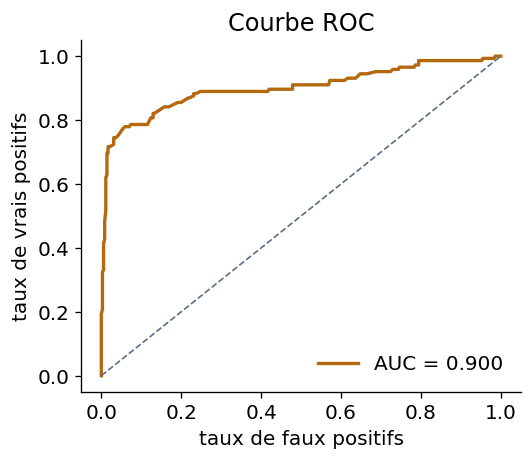

In [12]:
# Exercice 6 — corrigé.
fpr, tpr, _ = roc_curve(yte, proba)
aire = auc(fpr, tpr)
print(f"AUC = {aire:.3f}")

fig, ax = plt.subplots(figsize=(4.6, 4.0))
ax.plot(fpr, tpr, color=BRONZE, lw=2, label=f"AUC = {aire:.3f}")
ax.plot([0, 1], [0, 1], color=GRIS, ls="--", lw=1)
ax.set_xlabel("taux de faux positifs"); ax.set_ylabel("taux de vrais positifs")
ax.set_title("Courbe ROC"); ax.legend(frameon=False, loc="lower right")
fig.tight_layout(); plt.show()

**Indices :**
1. `roc_curve` prend la **vérité** puis les **probabilités** (pas les classes).
2. Elle rend trois valeurs ; on ignore la troisième avec `_`.
3. Presque la solution : `fpr, tpr, _ = roc_curve(yte, proba)` puis `aire = auc(fpr, tpr)`.

In [13]:
# ✅ Vérification exercice 6
assert "aire" in globals(), "Il manque aire : complète l'exercice 6."
assert 0.9 < aire <= 1.0, f"AUC attendue > 0.9, obtenu {aire:.3f}. Vérifie roc_curve(yte, proba)."
print(f"✅ Exercice 6 réussi : AUC = {aire:.3f} (bien au-dessus du hasard 0,5).")

✅ Exercice 6 réussi : AUC = 0.900 (bien au-dessus du hasard 0,5).


## Bilan du TP

Si les six ✅ sont verts, vous avez **entraîné et évalué vous-même** un détecteur de
phishing :

| Exo | Compétence | Chiffre du cours |
|---|---|---|
| 1 | Entraîner une régression logistique (scaler + pipeline) | 89.8 % |
| 2 | Entraîner une forêt aléatoire (200 arbres, graine) | 90.0 % |
| 3 | Prédire sur le test + matrice de confusion | 337/18/32/113 |
| 4 | Précision / rappel / F1 à la main | 0.863 / 0.779 / 0.819 |
| 5 | Le seuil arbitre sécurité / confort | 0,50 → P.952/R.683 |
| 6 | ROC / AUC, indépendant du seuil | AUC > 0.9 |

**Pour aller plus loin (bonus, non noté) :**
- Changez `GRAINE` en 7 dans la préparation : quels chiffres bougent ? Pourquoi ?
- Exercice 3 bis : vérifiez qu'aucune URL de test n'est dans l'entraînement
  (`set(itr) & set(ite)` doit être vide) — l'« anti-fuite ».
- Entraînez un **arbre seul** (`DecisionTreeClassifier`) : exactitude entraînement
  ~100 % mais test plus basse → le surapprentissage, mesuré.

**Corrigé :** `demo_tests_corrige.ipynb` (après avoir essayé).